In [1]:
from data_analysis_utils import *

# No TDD, no refinement
DEFAULT_PREFIX = "default"
DEFAULT_SUBFOLDERS = ["default_0_54", "default_55_109", "default_110_163"]

# No TDD, refinement
REF_PREFIX = "refine"
REF_SUBFOLDERS = ["REF_0_54", "REF_55_109", "REF_110_163"]

# TDD, no refinement
TDD_PREFIX = "tdd"
TDD_SUBFOLDERS = ["tdd_0_50", "tdd_51_105", "tdd_106_163"]

# TDD, refinement
TDD_REF_PREFIX = "tdd_refine"
TDD_REF_SUBFOLDERS = ["TDD_REF_0_54", "TDD_REF_55_109", "TDD_REF_110_163"]

AGENT_SCENARIOS = {
    "default": (DEFAULT_PREFIX, DEFAULT_SUBFOLDERS),
    "refine": (REF_PREFIX, REF_SUBFOLDERS),
    "tdd": (TDD_PREFIX, TDD_SUBFOLDERS), 
    "tdd_refine": (TDD_REF_PREFIX, TDD_REF_SUBFOLDERS),
}


In [2]:
import sys
sys.path.insert(0, '..')

from recheck_data import recheck_data

# There is probably a much better way to do this, but i am hardcoding it for now
instance_numbers = {
  "default_0_54": {
    "start": 0,
    "end": 54,
  },
  "default_55_109": {
    "start": 55,
    "end": 109,
  },
  "default_110_163": {
    "start": 110,
    "end": 163,
  },
  "tdd_0_50": {
    "start": 0,
    "end": 50,
  },
  "tdd_51_105": {
    "start": 51,
    "end": 105,
  },
  "tdd_106_163": {
    "start": 106,
    "end": 163,
  },
  "TDD_REF_0_54": {
    "start": 0,
    "end": 54,
  },
  "TDD_REF_55_109": {
    "start": 55,
    "end": 109,
  },
  "TDD_REF_110_163": {
    "start": 110,
    "end": 163,
  },
  "REF_0_54": {
    "start": 0,
    "end": 54,
  },
  "REF_55_109": {
    "start": 55,
    "end": 109,
  },
  "REF_110_163": {
    "start": 110,
    "end": 163,
  },
}

for scenario, (prefix, subfolders) in AGENT_SCENARIOS.items():
  for subfolder in subfolders:
    recheck_data(prefix, subfolder, instance_numbers.get(subfolder)["start"], instance_numbers.get(subfolder)["end"])

In [3]:
df_summaries = aggregate_json(agent_scenarios=AGENT_SCENARIOS)

#df_default = aggregate_csv(prefix=DEFAULT_PREFIX, subfolders=DEFAULT_SUBFOLDERS)
df_instances = aggregate_csv_scenarios(AGENT_SCENARIOS)
df_instances = add_unrolled_token_cost_column(df_instances)

Visited folder:  .\default\default_0_54
Visited folder:  .\default\default_55_109
Visited folder:  .\default\default_110_163
default input token total: 58208
default output token total: 26083
Visited folder:  .\refine\REF_0_54
Visited folder:  .\refine\REF_55_109
Visited folder:  .\refine\REF_110_163
refine input token total: 269671
refine output token total: 79475
Visited folder:  .\tdd\tdd_0_50
Visited folder:  .\tdd\tdd_51_105
Visited folder:  .\tdd\tdd_106_163
tdd input token total: 370953
tdd output token total: 92013
Visited folder:  .\tdd_refine\TDD_REF_0_54
Visited folder:  .\tdd_refine\TDD_REF_55_109
Visited folder:  .\tdd_refine\TDD_REF_110_163
tdd_refine input token total: 738597
tdd_refine output token total: 129570
default -> refine: input=363.29%, output=204.70%
default -> tdd: input=537.29%, output=252.77%
default -> tdd_refine: input=1168.89%, output=396.76%
refine -> default: input=-78.42%, output=-67.18%
refine -> tdd: input=37.56%, output=15.78%
refine -> tdd_refine:

In [4]:
df_summaries.head()

,total,passed,pass_rate,avg_iters,tokens_input,tokens_output,avg_line_coverage,avg_branch_coverage,avg_mutation_score,tokens_a11_input,tokens_a11_output,tokens_a12_input,tokens_a12_output,tokens_a2_input,tokens_a2_output,tokens_a3_input,tokens_a3_output,tokens_a4_input,tokens_a4_output
scenario,,,,,,,,,,,,,,,,,,,
default,164,133,0.810976,1.000000,3184384,1429468,0.000000,0.0,-1.0,0,0,0,0,2197312,1099977,987072,329491,0,0
refine,164,120,0.731707,1.812121,14730140,4346696,0.000000,0.0,-1.0,0,0,0,0,5750910,2168885,1196078,110979,7783152,2066832
tdd,164,130,0.792683,1.000000,20429859,5077307,47.113394,0.0,-1.0,5361415,1460171,10296890,2906320,4610024,668708,161530,42108,0,0
tdd_refine,164,135,0.823171,1.930079,40294687,7071791,47.112789,0.0,-1.0,5334202,1402137,9800003,2789009,14160414,1386577,129294,35783,10870774,1458285


In [5]:
df_instances.head()

,scenario,batch,passed_hidden_tests,new_line_coverage,new_branch_coverage,pipeline_tests_passed,pipeline_iterations,coverage_tests_run,coverage_tests_failed,coverage_tests_errors,...,a12_output_tokens,a2_input_tokens,a2_output_tokens,a3_input_tokens,a3_output_tokens,a4_input_tokens,a4_output_tokens,instance_id,token_cost_cumulative,token_cost_unrolled
0,default,default_0_54,True,NaN,NaN,False,1,0,0,0,...,0,230,72,0,0,0,0,1,302,302.0
1,default,default_0_54,True,NaN,NaN,False,1,0,0,0,...,0,451,199,0,0,0,0,2,650,348.0
2,default,default_0_54,True,NaN,NaN,False,1,0,0,0,...,0,642,212,229,26,0,0,3,1109,459.0
3,default,default_0_54,True,NaN,NaN,False,1,0,0,0,...,0,867,266,229,26,0,0,4,1388,279.0
4,default,default_0_54,True,NaN,NaN,False,1,0,0,0,...,0,1090,335,229,26,0,0,5,1680,292.0


In [6]:
# Generate tables for paper results

group_col = "scenario"

print("Pass rate:")
display(df_summaries)

print("Token cost:")
token_cost_summary = summarize_numeric_by_group(df_instances, group_col, "token_cost_unrolled")
display(token_cost_summary)

print("Number of iterations:")
iterations_summary = summarize_numeric_by_group(df_instances, group_col, "pipeline_iterations")
display(iterations_summary)

print("Test quality (line coverage, branch coverage, mutation score)")
linecov_summary = summarize_numeric_by_group(df_instances, group_col, "new_line_coverage", drop_negative=True)
branchcov_summary = summarize_numeric_by_group(df_instances, group_col, "new_branch_coverage", drop_negative=True)
mutation_summary = summarize_numeric_by_group(df_instances, group_col, "mutation_score", drop_negative=True)
display(linecov_summary)
display(branchcov_summary)
display(mutation_summary)

Pass rate:


,total,passed,pass_rate,avg_iters,tokens_input,tokens_output,avg_line_coverage,avg_branch_coverage,avg_mutation_score,tokens_a11_input,tokens_a11_output,tokens_a12_input,tokens_a12_output,tokens_a2_input,tokens_a2_output,tokens_a3_input,tokens_a3_output,tokens_a4_input,tokens_a4_output
scenario,,,,,,,,,,,,,,,,,,,
default,164,133,0.810976,1.000000,3184384,1429468,0.000000,0.0,-1.0,0,0,0,0,2197312,1099977,987072,329491,0,0
refine,164,120,0.731707,1.812121,14730140,4346696,0.000000,0.0,-1.0,0,0,0,0,5750910,2168885,1196078,110979,7783152,2066832
tdd,164,130,0.792683,1.000000,20429859,5077307,47.113394,0.0,-1.0,5361415,1460171,10296890,2906320,4610024,668708,161530,42108,0,0
tdd_refine,164,135,0.823171,1.930079,40294687,7071791,47.112789,0.0,-1.0,5334202,1402137,9800003,2789009,14160414,1386577,129294,35783,10870774,1458285


Token cost:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,513.969512,323.0,1468.664547,187.0,18746.0
refine,164,2128.939024,1917.5,2117.172851,469.0,18448.0
tdd,164,2822.963415,2654.0,868.683285,1771.0,9251.0
tdd_refine,164,5293.701220,2892.5,4744.908109,1754.0,19671.0


Number of iterations:


,count,mean,median,std,min,max
scenario,,,,,,
default,164,1.000000,1.0,0.000000,1,1
refine,164,1.810976,2.0,0.943626,1,5
tdd,164,1.000000,1.0,0.000000,1,1
tdd_refine,164,1.926829,1.0,1.595857,1,5


Test quality (line coverage, branch coverage, mutation score)


,count,mean,median,std,min,max
scenario,,,,,,
tdd,164,95.990976,100.0,11.645083,10.0,100.0
tdd_refine,163,96.446258,100.0,11.506588,20.0,100.0


,count,mean,median,std,min,max
scenario,,,,,,
tdd,164,93.972683,100.0,14.108317,0.0,100.0
tdd_refine,163,94.143497,100.0,15.118575,0.0,100.0


,count,mean,median,std,min,max
scenario,,,,,,
tdd,136,0.854031,0.93095,0.208290,0.0,1.0
tdd_refine,137,0.848239,0.92860,0.213455,0.0,1.0


In [7]:
print("We compare influence of TDD and pass rates with pair wise Fischer tests")
print("TDD influence on pass rate")
display(compare_pass_rates(df_summaries, "default", "tdd"))
display(compare_pass_rates(df_summaries, "refine", "tdd_refine"))

print("Refinement influence on pass rate")
display(compare_pass_rates(df_summaries, "default", "refine"))
display(compare_pass_rates(df_summaries, "tdd", "tdd_refine"))


We compare influence of TDD and pass rates with pair wise Fischer tests
TDD influence on pass rate


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,default,tdd,passed,0.810976,0.792683,164.0,164.0,133.0,130.0,0.781924,False


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,refine,tdd_refine,passed,0.731707,0.823171,164.0,164.0,120.0,135.0,0.062659,False


Refinement influence on pass rate


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,default,refine,passed,0.810976,0.731707,164.0,164.0,133.0,120.0,0.114269,False


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,tdd,tdd_refine,passed,0.792683,0.823171,164.0,164.0,130.0,135.0,0.575266,False


In [8]:
print("We compare influence of TDD and refinement on token cost with MannWhitney U tests")

print("TDD influence on token costs")
display(compare_token_costs(df_instances, "default", "tdd"))
display(compare_token_costs(df_instances, "refine", "tdd_refine"))

print("Refinement influence on token costs")
display(compare_token_costs(df_instances, "default", "refine"))
display(compare_token_costs(df_instances, "tdd", "tdd_refine"))

We compare influence of TDD and refinement on token cost with MannWhitney U tests
TDD influence on token costs


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,tdd,token_cost_unrolled,513.969512,2822.963415,2.419354e-53,True


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,refine,tdd_refine,token_cost_unrolled,2128.939024,5293.70122,1.337314e-22,True


Refinement influence on token costs


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,refine,token_cost_unrolled,513.969512,2128.939024,8.359113e-49,True


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd,tdd_refine,token_cost_unrolled,2822.963415,5293.70122,0.000339,True


In [9]:
print("We compare influence of test quality on pass rate")

df_test_quality = df_instances.copy()
df_test_quality["passed_partition"] = df_test_quality["scenario"] + "_" + df_test_quality["passed_hidden_tests"].astype(str)

print("Influence of test quality on pass rate for TDD with refinement:")
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="new_line_coverage", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="new_branch_coverage", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_refine_True", "tdd_refine_False", group_col="passed_partition", metric_col="mutation_score", drop_negative=True))

print("Influence of test quality on pass rate for TDD w/o refinement")
display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="new_line_coverage", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="new_branch_coverage", drop_negative=False))
display(compare_quality_metric(df_test_quality, "tdd_True", "tdd_False", group_col="passed_partition", metric_col="mutation_score", drop_negative=True))

We compare influence of test quality on pass rate
Influence of test quality on pass rate for TDD with refinement:


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,new_line_coverage,97.589926,90.932143,NaN,False


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,new_branch_coverage,95.444296,87.871786,NaN,False


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_refine_True,tdd_refine_False,mutation_score,0.843856,0.879182,0.772378,False


Influence of test quality on pass rate for TDD w/o refinement


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_True,tdd_False,new_line_coverage,97.804769,89.055882,0.038462,True


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_True,tdd_False,new_branch_coverage,95.335846,88.760588,0.246703,False


,passed_partition,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,tdd_True,tdd_False,mutation_score,0.844532,0.898358,0.441607,False


In [10]:
print("We compare influence of test quality on token cost")

print("Influence of test quality on cost with TDD with refinement")
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "new_line_coverage", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "new_branch_coverage", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd_refine", "mutation_score", "token_cost_unrolled", drop_negative=True))

print("Influence of test quality on cost with TDD w/o refinement")
display(compare_metric_spearman_rho(df_test_quality, "tdd", "new_line_coverage", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd", "new_branch_coverage", "token_cost_unrolled"))
display(compare_metric_spearman_rho(df_test_quality, "tdd", "mutation_score", "token_cost_unrolled", drop_negative=True))

We compare influence of test quality on token cost
Influence of test quality on cost with TDD with refinement


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,new_line_coverage,token_cost_unrolled,96.446258,5293.70122,NaN,NaN,False


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,new_branch_coverage,token_cost_unrolled,94.143497,5293.70122,NaN,NaN,False


,tdd_refine,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd_refine,mutation_score,token_cost_unrolled,0.848239,3966.554745,-0.113284,0.187484,False


Influence of test quality on cost with TDD w/o refinement


,tdd,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd,new_line_coverage,token_cost_unrolled,95.990976,2822.963415,0.047242,0.548038,False


,tdd,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd,new_branch_coverage,token_cost_unrolled,93.972683,2822.963415,0.033013,0.674734,False


,tdd,left_metric,right_metric,left_mean,right_mean,spearmanr_stat,p_value,significant_0.05
0,tdd,mutation_score,token_cost_unrolled,0.854031,2812.382353,-0.143765,0.094963,False


,scenario,comparison_group,metric,left_rate,right_rate,n_left,n_right,successes_left,successes_right,p_value,significant_0.05
0,default,refine,passed,0.810976,0.731707,164.0,164.0,133.0,120.0,0.114269,False


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,refine,token_cost_unrolled,513.969512,2128.939024,8.359113e-49,True


,scenario,comparison_group,metric,left_mean,right_mean,p_value,significant_0.05
0,default,refine,pipeline_iterations,1.0,1.810976,3.296009e-30,True


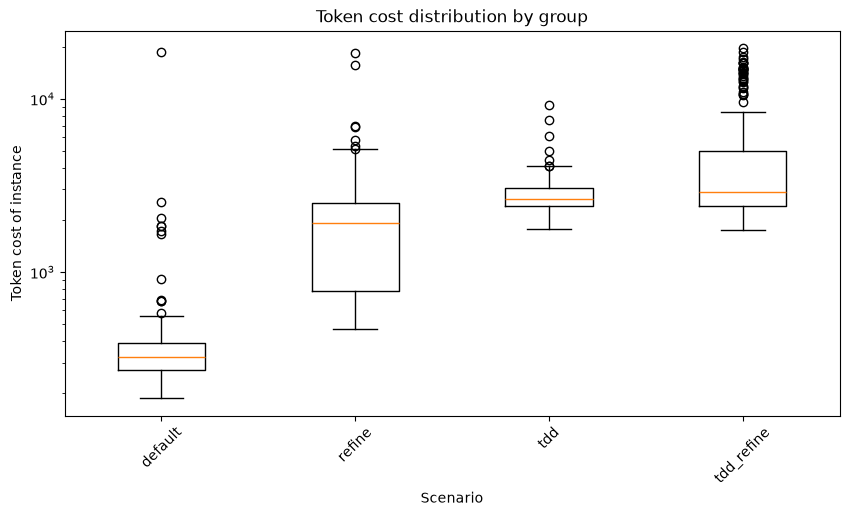

In [11]:
# Analyze and compare probability distributions of metrics in different scenarios

ax = plot_token_cost_distribution(df_instances, group_col=group_col)
# axes = plot_metric_relationships(df_instances, group_col=group_col)

scenario_names = list(df_instances["scenario"].dropna().unique())
if len(scenario_names) >= 2:
    display(compare_pass_rates(df_summaries, scenario_names[0], scenario_names[1]))
    display(compare_token_costs(df_instances, scenario_names[0], scenario_names[1]))
    display(compare_quality_metric(df_instances, scenario_names[0], scenario_names[1], metric_col="pipeline_iterations"))
else:
    print("Only one scenario is present in AGENT_SCENARIOS. Add another scenario to run cross-scenario significance tests.")
